# KNN known-attack classifier — held-out testing
Removes BENIGN before sampling exactly 1,200 test attack records. Loads the frozen supervised classifier.


In [9]:
from pathlib import Path
import sys, json, importlib.util
import numpy as np
import pandas as pd
import joblib
ROOT=Path.cwd().resolve()
if ROOT.name.lower()=='knn_known' and ROOT.parent.name.lower()=='notebooks': ROOT=ROOT.parent.parent
elif ROOT.name.lower()=='notebooks': ROOT=ROOT.parent
MODULE_DIR=ROOT/'notebooks'/'knn_known'
if not (MODULE_DIR/'knn_known_flow.py').exists():
    MODULE_DIR=Path.cwd().resolve()
if not (MODULE_DIR / 'knn_known_flow.py').is_file():
    raise FileNotFoundError(f'Missing module: {MODULE_DIR / "knn_known_flow.py"}')
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))
# Load this exact file, avoiding stale Jupyter module cache.
spec = importlib.util.spec_from_file_location('knn_known_flow', MODULE_DIR / 'knn_known_flow.py')
knn_module = importlib.util.module_from_spec(spec)
sys.modules['knn_known_flow'] = knn_module
spec.loader.exec_module(knn_module)
read_data = knn_module.read_data
choose_columns = knn_module.choose_columns
feature_frame = knn_module.feature_frame
build_pipeline = knn_module.build_pipeline
save_artifact = knn_module.save_artifact
load_artifact = knn_module.load_artifact
predict_rows = knn_module.predict_rows
stratified_sample = knn_module.stratified_sample
print('Loaded KNN helper:', knn_module.__file__)
DATA=ROOT/'data'/'processed'/'Data_V3_SSH_Unknown_final'
MODEL=ROOT/'saved-models'/'knn_known'/'known_classifier.joblib'
OUT=ROOT/'outputs'/'results'/'knn_known'
FIG=ROOT/'outputs'/'figures'/'knn_known'
OUT.mkdir(parents=True,exist_ok=True);FIG.mkdir(parents=True,exist_ok=True)
print('Root:',ROOT)
print('Model:',MODEL)

Loaded KNN helper: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\notebooks\knn_known\knn_known_flow.py
Root: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection
Model: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\saved-models\knn_known\known_classifier.joblib


known_test.parquet: filtered 876 attempted rows
Removed BENIGN test rows: 213767
Test attack records: 1200 | Selected k: 3
                            precision    recall  f1-score   support

                    Botnet       1.00      1.00      1.00         3
                      DDoS       1.00      1.00      1.00       292
             DoS GoldenEye       1.00      0.92      0.96        24
                  DoS Hulk       1.00      1.00      1.00       487
             DoS Slowloris       0.86      1.00      0.92        12
                Heartbleed       1.00      1.00      1.00         1
              Infiltration       1.00      1.00      1.00         1
   Infiltration - Portscan       0.91      0.91      0.91       113
                  Portscan       0.96      0.96      0.96       264
  Web Attack - Brute Force       0.00      0.00      0.00         1
Web Attack - SQL Injection       1.00      1.00      1.00         1
          Web Attack - XSS       1.00      1.00      1.00   

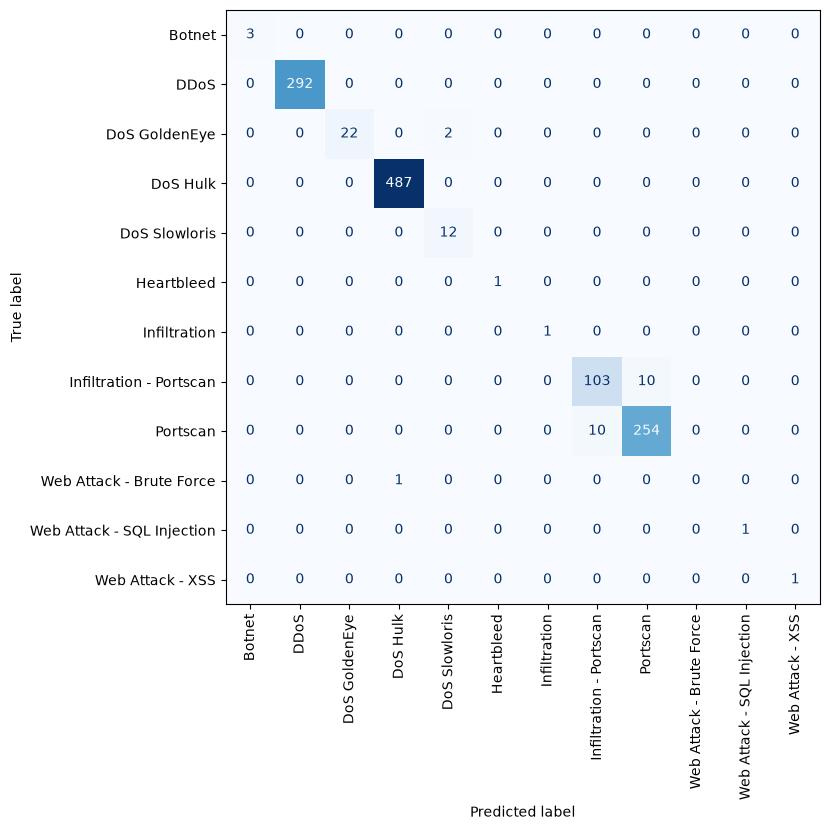

In [10]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

if not MODEL.exists():
    raise FileNotFoundError("Run knn_known_training.ipynb first")
artifact = load_artifact(MODEL)
if any(str(c).casefold() == "benign" for c in artifact["classes"]):
    raise ValueError("Saved classifier still includes BENIGN. Retrain using the updated training notebook.")

test = read_data(DATA / "known_test.parquet")
labels = test["Label"].astype(str).str.strip()
benign_mask = labels.str.casefold().eq("benign")
print("Removed BENIGN test rows:", int(benign_mask.sum()))
test = test.loc[~benign_mask].copy().reset_index(drop=True)
if len(test) < 1200:
    raise ValueError(f"Only {len(test)} attack test rows; cannot sample 1,200")
test = stratified_sample(test, 1200, seed=44, preserve_rare=False)
y_true = test["Label"].astype(str).str.strip()
unknown_labels = sorted(set(y_true) - set(artifact["classes"]))
if unknown_labels:
    print("WARNING: Test labels not seen during training:", unknown_labels)

X_test = feature_frame(test, artifact["columns"])
# One neighbor search rather than separate predict and predict_proba calls.
prob = artifact["model"].predict_proba(X_test)
y_pred = artifact["model"].classes_[np.argmax(prob, axis=1)]
print("Test attack records:", len(test), "| Selected k:", artifact["config"]["best_k"])
print(classification_report(y_true, y_pred, zero_division=0))
metrics = {
    "test_rows": len(test),
    "benign_excluded": True,
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
}
print(json.dumps(metrics, indent=2))
(OUT / "known_test_metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
pd.DataFrame({"actual": y_true, "predicted": y_pred,
              "confidence": prob.max(axis=1)}).to_csv(OUT / "known_test_predictions.csv", index=False)
labels_plot = sorted(set(y_true) | set(y_pred))
fig, ax = plt.subplots(figsize=(max(7, len(labels_plot)*0.7), max(6, len(labels_plot)*0.7)))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=labels_plot,
                                        xticks_rotation=90, ax=ax, cmap="Blues", colorbar=False)
fig.tight_layout()
fig.savefig(FIG / "known_test_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
